# 12 - CRISP-DM ile Uçtan Uca Akış: Ham Veri → Eksik (Null) Veri Ayrımı → `predict()` ile Tahminleme

Bu notebook üç soruya cevap verir:

1. **`predict` nedir, tahminlemede nerede kullanılır?**
2. **Ham bir veriyi toplayıp null (eksik) kayıtları nasıl ayırırız?**
3. **Tüm bu süreç CRISP-DM adımlarıyla nasıl sıralanır?** (görsellerle)

Kullanılan veri: `eksik_data.csv` (ham veri, `yas` kolonunda eksikler var) ve karşılaştırma için `data.csv` (aynı verinin eksiksiz hali).

## 📌 `predict()` Nedir?

Scikit-learn'de (ve çoğu ML kütüphanesinde) bir modelin yaşam döngüsü iki ana metottan oluşur:

| Metot | Ne yapar? | Ne zaman? |
|---|---|---|
| `model.fit(X_train, y_train)` | Model **öğrenir** (katsayıları / kuralları bulur) | Eğitim aşaması |
| `model.predict(X_yeni)` | Öğrenilen bilgiyle **yeni veriler için çıktı üretir** | Test, değerlendirme, canlı kullanım |
| `model.predict_proba(X_yeni)` | Sınıflandırmada her sınıfın **olasılığını** verir | Risk skoru, eşik ayarı |
| `transformer.transform(X)` | Veriyi dönüştürür (ölçekleme, encoding, imputing) | Ön işleme |

> Kısaca: **`fit` = öğren, `predict` = uygula.** `predict` modelin görmediği bir girdiye (X) bakıp hedef değeri (ŷ) tahmin eder.

### `predict` tahminlemede nerelerde kullanılır?

| Kullanım alanı | Örnek | Çıktı türü |
|---|---|---|
| **Regresyon** | Ev fiyatı, kilo, satış miktarı tahmini | Sürekli sayı |
| **Sınıflandırma** | Cinsiyet, churn (müşteri kaybı), spam / değil | Sınıf etiketi |
| **Zaman serisi (forecast)** | Gelecek ayın satışı, talep tahmini | Gelecek değerler |
| **Eksik veri doldurma (imputation)** | Null olan `yas` değerini diğer kolonlardan tahmin etme | Doldurulmuş değer |
| **Model değerlendirme** | `y_pred = model.predict(X_test)` → accuracy, RMSE | Metrik hesaplama |
| **Canlıya alma (deployment)** | API'ye gelen yeni müşteri için anlık skor | Gerçek zamanlı tahmin |

Bu notebook'ta `predict`'i **iki yerde** kullanacağız: (1) eksik `yas` değerlerini tahmin ederek doldurmak, (2) `cinsiyet` sınıflandırması yapmak.

## 🔄 CRISP-DM Süreci (Görsel)

**CRISP-DM** (Cross-Industry Standard Process for Data Mining), veri bilimi projelerinde en yaygın kullanılan 6 adımlı döngüsel süreçtir. Aşağıdaki hücre süreci çizer; notebook'un geri kalanı bu sırayı takip eder.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Circle, FancyArrowPatch

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

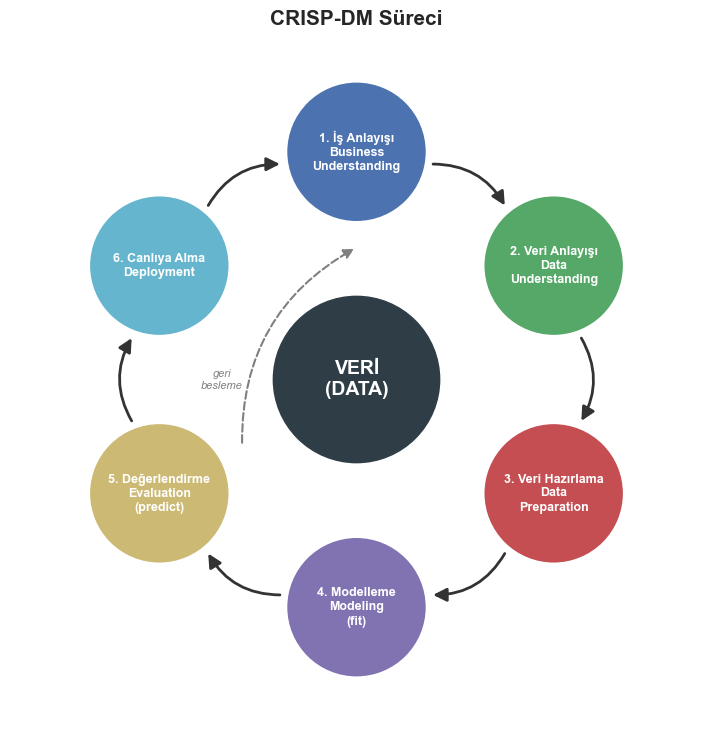

In [2]:
def crisp_dm_ciz(aktif=None):
    # CRISP-DM döngüsünü çizer. aktif: vurgulanacak adımın indeksi (0-5)
    adimlar = [
        ("1. İş Anlayışı\nBusiness\nUnderstanding", "#4C72B0"),
        ("2. Veri Anlayışı\nData\nUnderstanding", "#55A868"),
        ("3. Veri Hazırlama\nData\nPreparation", "#C44E52"),
        ("4. Modelleme\nModeling\n(fit)", "#8172B2"),
        ("5. Değerlendirme\nEvaluation\n(predict)", "#CCB974"),
        ("6. Canlıya Alma\nDeployment", "#64B5CD"),
    ]
    n, R, r = len(adimlar), 1.15, 0.36
    acilar = np.pi / 2 - np.arange(n) * 2 * np.pi / n

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.set_xlim(-1.75, 1.75); ax.set_ylim(-1.75, 1.75); ax.set_aspect("equal"); ax.axis("off")

    ax.add_patch(Circle((0, 0), 0.42, color="#2F3E46", zorder=3))
    ax.text(0, 0, "VERİ\n(DATA)", ha="center", va="center", color="white", fontsize=14, fontweight="bold", zorder=4)

    for i, ((metin, renk), a) in enumerate(zip(adimlar, acilar)):
        x, y = R * np.cos(a), R * np.sin(a)
        alpha = 1.0 if (aktif is None or aktif == i) else 0.25
        ax.add_patch(Circle((x, y), r, color=renk, alpha=alpha, ec="black" if aktif == i else None, lw=3))
        yazi_renk = "white" if alpha == 1.0 else "#555555"
        ax.text(x, y, metin, ha="center", va="center", color=yazi_renk, fontsize=9, fontweight="bold")
        a2, d = acilar[(i + 1) % n], 0.33
        bas = (R * np.cos(a - d), R * np.sin(a - d))
        son = (R * np.cos(a2 + d), R * np.sin(a2 + d))
        ax.add_patch(FancyArrowPatch(bas, son, arrowstyle="-|>", mutation_scale=20,
                                     connectionstyle="arc3,rad=-0.3", color="#333333", lw=2))

    # Geri besleme oku: Değerlendirme -> İş Anlayışı
    p4 = (R * np.cos(acilar[4]) * 0.58, R * np.sin(acilar[4]) * 0.58)
    p0 = (R * np.cos(acilar[0]) * 0.58, R * np.sin(acilar[0]) * 0.58)
    ax.add_patch(FancyArrowPatch(p4, p0, arrowstyle="-|>", mutation_scale=15, linestyle="--",
                                 connectionstyle="arc3,rad=-0.3", color="gray", lw=1.5, zorder=1))
    ax.text(-0.68, 0.0, "geri\nbesleme", ha="center", va="center", color="gray", fontsize=8, style="italic")
    baslik = "CRISP-DM Süreci" if aktif is None else f"CRISP-DM → Şu an: {adimlar[aktif][0].split(chr(10))[0]}"
    ax.set_title(baslik, fontsize=15, fontweight="bold")
    plt.show()

crisp_dm_ciz()

**Yorum:** Döngü 6 adımdan oluşur ve oklar saat yönünde ilerler. Kesikli gri ok, **Değerlendirme** sonuçları yetersizse **İş Anlayışı**'na geri dönüldüğünü gösterir — CRISP-DM doğrusal değil, **iteratif** bir süreçtir. Tahminleme açısından kritik nokta: `fit` **Modelleme** adımında, `predict` ise **Değerlendirme** ve **Canlıya Alma** adımlarında kullanılır.

---
## 1️⃣ İş Anlayışı (Business Understanding)

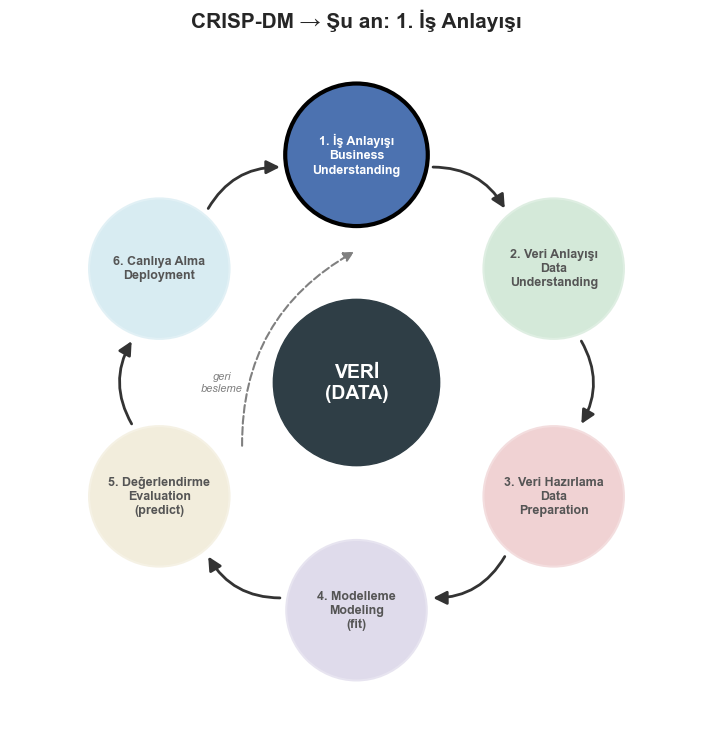

In [3]:
crisp_dm_ciz(aktif=0)

**Problem tanımı:**

- **Amaç:** Bir kişinin `ulke`, `boy`, `kilo`, `yas` bilgilerinden **cinsiyetini** (`e` / `k`) tahmin etmek → **Sınıflandırma** problemi.
- **Yan amaç:** Ham veride eksik olan `yas` değerlerini kaybetmeden doldurmak (gerekirse `predict` ile).
- **Başarı kriteri:** Test setinde doğruluk (accuracy) ve karışıklık matrisi (confusion matrix).
- **Kısıt:** Veri çok küçük (22 satır) → sonuçlar **eğitim amaçlıdır**, genellenebilirliği sınırlıdır.

---
## 2️⃣ Veri Anlayışı (Data Understanding) — Ham Veriyi Toplama

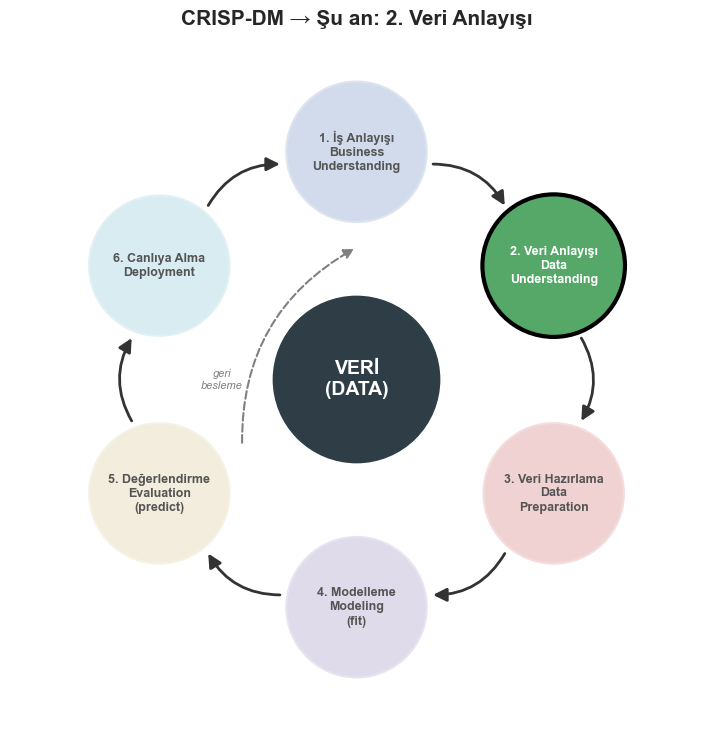

In [4]:
crisp_dm_ciz(aktif=1)

### Ham veri nereden toplanır?

Gerçek projelerde ham veri; **CSV/Excel dosyaları**, **veritabanları (SQL)**, **API'ler**, **web scraping**, **sensör/log** kayıtları gibi kaynaklardan gelir. Hangi kaynak olursa olsun ilk iş onu bir `DataFrame`'e almaktır.

⚠️ **Önemli:** Ham veride eksik değerler her zaman boş hücre olarak gelmez. `"?"`, `"NA"`, `"null"`, `"None"`, `"-"` gibi metinler de aslında eksiktir. `na_values` parametresiyle bunları okuma anında `NaN`'a çeviririz.

In [3]:
# Ham veriyi topla (oku). Gizli null gösterimlerini de NaN'a çeviriyoruz.
GIZLI_NULLAR = ["", "?", "NA", "N/A", "null", "NULL", "None", "-"]
ham_veri = pd.read_csv("eksik_data.csv", na_values=GIZLI_NULLAR)

print("Boyut (satır, kolon):", ham_veri.shape)
ham_veri.head(10)

Boyut (satır, kolon): (22, 5)


,ulke,boy,kilo,yas,cinsiyet
0,tr,130,30,10.0,e
1,tr,125,36,11.0,e
2,tr,135,34,10.0,k
3,tr,133,30,9.0,k
4,tr,129,38,12.0,e
5,tr,180,90,30.0,e
6,tr,190,80,25.0,e
7,tr,175,90,35.0,e
8,tr,177,60,22.0,k
9,us,185,105,33.0,e


**Yorum:** Veri 22 satır ve 5 kolondan oluşuyor: `ulke` (kategorik: tr/us/fr), `boy`, `kilo`, `yas` (sayısal) ve hedef değişken `cinsiyet` (e/k).

In [6]:
# Kolon tipleri ve dolu (non-null) değer sayıları
ham_veri.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ulke      22 non-null     object 
 1   boy       22 non-null     int64  
 2   kilo      22 non-null     int64  
 3   yas       20 non-null     float64
 4   cinsiyet  22 non-null     object 
dtypes: float64(1), int64(2), object(2)
memory usage: 1012.0+ bytes


**Yorum:** `info()` çıktısında `yas` kolonunun **20 non-null** değeri var; toplam 22 satır olduğuna göre **2 eksik** değer bulunuyor. `yas` tipinin `float64` olması da bir ipucudur: pandas, `NaN` içeren tam sayı kolonlarını float'a çevirir.

### Null değerleri tespit etme

| Komut | Ne verir? |
|---|---|
| `df.isnull()` / `df.isna()` | Her hücre için True/False maskesi |
| `df.isnull().sum()` | Kolon bazında eksik sayısı |
| `df.isnull().mean()*100` | Kolon bazında eksik yüzdesi |
| `df.isnull().any(axis=1)` | Satırda **en az bir** eksik var mı? |

In [4]:
eksik_ozet = pd.DataFrame({
    "eksik_sayisi": ham_veri.isnull().sum(),
    "eksik_yuzdesi_%": (ham_veri.isnull().mean() * 100).round(2),
})
eksik_ozet

,eksik_sayisi,eksik_yuzdesi_%
ulke,0,0.00
boy,0,0.00
kilo,0,0.00
yas,2,9.09
cinsiyet,0,0.00


**Yorum:** Yalnızca `yas` kolonunda eksik var: **2 değer (%9.09)**. Diğer kolonlar tam. %10'un altındaki eksiklik genellikle doldurma (imputation) ile rahatça yönetilebilir.

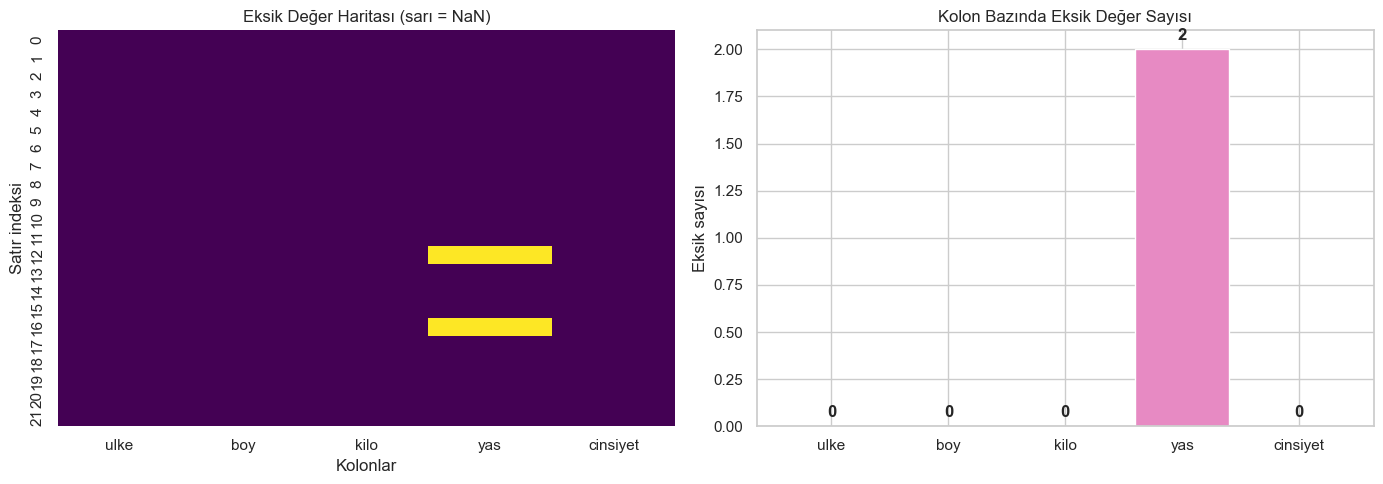

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: Eksik değer haritası (sarı = eksik)
sns.heatmap(ham_veri.isnull(), cbar=False, cmap="viridis", yticklabels=True, ax=axes[0])
axes[0].set_title("Eksik Değer Haritası (sarı = NaN)")
axes[0].set_xlabel("Kolonlar"); axes[0].set_ylabel("Satır indeksi")

# Sağ: Kolon bazında eksik sayısı
renkler = sns.color_palette("Set2", len(eksik_ozet))
axes[1].bar(eksik_ozet.index, eksik_ozet["eksik_sayisi"], color=renkler)
axes[1].set_title("Kolon Bazında Eksik Değer Sayısı")
axes[1].set_ylabel("Eksik sayısı")
for i, v in enumerate(eksik_ozet["eksik_sayisi"]):
    axes[1].text(i, v + 0.05, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Yorum:** Isı haritasında sarı çizgiler eksik hücreleri gösterir: `yas` kolonunda **satır 12 ve 16**. Eksikler rastgele dağılmış görünüyor (belirli bir ülke veya bloğa yığılmamış); bu da doldurmanın makul olduğunu destekler.

### 🔀 Null kayıtları temiz kayıtlardan AYIRMA

Mantık basit: bir **boolean maske** oluşturup veriyi ikiye bölüyoruz.

```
null_maske = df.isnull().any(axis=1)   # en az bir NaN içeren satırlar → True
df_null    = df[null_maske]            # eksik kayıtlar
df_temiz   = df[~null_maske]           # tam kayıtlar  (≡ df.dropna())
```

In [9]:
null_maske = ham_veri.isnull().any(axis=1)

df_null = ham_veri[null_maske]      # Eksik içeren satırlar
df_temiz = ham_veri[~null_maske]    # Tamamen dolu satırlar

print(f"Toplam satır : {len(ham_veri)}")
print(f"Temiz satır  : {len(df_temiz)}")
print(f"Null satır   : {len(df_null)}")
print("\nNull içeren kayıtlar:")
df_null

Toplam satır : 22
Temiz satır  : 20
Null satır   : 2

Null içeren kayıtlar:


,ulke,boy,kilo,yas,cinsiyet
12,us,160,58,NaN,k
16,fr,193,90,NaN,e


**Yorum:** 22 satır → **20 temiz** + **2 null** kayıt olarak ayrıldı. Eksik kayıtlar: `us, 160 cm, 58 kg, k` (satır 12) ve `fr, 193 cm, 90 kg, e` (satır 16). Bu kayıtların diğer kolonları dolu olduğu için onları **atmak yerine doldurmak** bilgi kaybını önler.

In [10]:
# Kontrol: maske ile ayırmak, dropna() ile aynı sonucu verir mi?
print("df_temiz == dropna() :", df_temiz.equals(ham_veri.dropna()))

# Ayrıca sadece belirli bir kolona göre ayırma:
print("Sadece 'yas' kolonu eksik olanlar:", ham_veri[ham_veri["yas"].isnull()].index.tolist())

df_temiz == dropna() : True
Sadece 'yas' kolonu eksik olanlar: [12, 16]


**Yorum:** Maske ile ayrım `dropna()` ile birebir aynı sonucu verir. Gerçek projelerde birden fazla kolonda eksik olabileceği için `df[df["kolon"].isnull()]` ile kolon bazlı filtreleme de çok kullanılır.

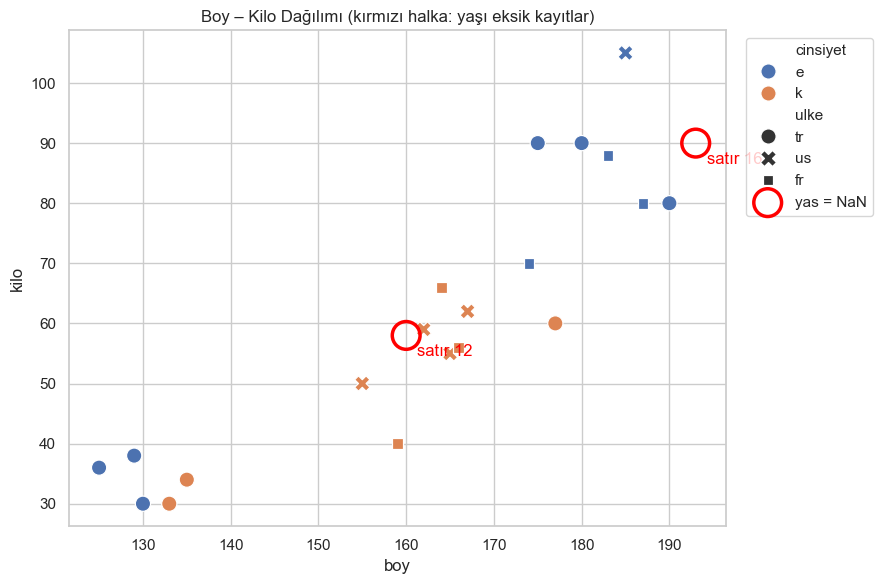

In [11]:
# Null kayıtların, temiz verinin dağılımında nerede durduğunu görelim
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df_temiz, x="boy", y="kilo", hue="cinsiyet", style="ulke",
                palette={"e": "#4C72B0", "k": "#DD8452"}, s=120, ax=ax)
ax.scatter(df_null["boy"], df_null["kilo"], s=400, facecolors="none", edgecolors="red", linewidths=2.5,
           label="yas = NaN")
for idx, row in df_null.iterrows():
    ax.annotate(f"satır {idx}", (row["boy"], row["kilo"]), xytext=(8, -15), textcoords="offset points", color="red")
ax.set_title("Boy – Kilo Dağılımı (kırmızı halka: yaşı eksik kayıtlar)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Yorum:** Eksik kayıtlar veri bulutunun içinde, uç değer (outlier) değiller. Erkekler (`e`) genelde daha uzun ve kilolu bölgede, kadınlar (`k`) daha alt bölgede kümeleniyor — bu, `boy` ve `kilo`nun cinsiyet tahmininde faydalı olacağının ilk işaretidir. Sol alttaki küme (boy ~125-135) çocuk yaşlardaki (9-12) kayıtlardır.

---
## 3️⃣ Veri Hazırlama (Data Preparation) — Null'ları Ne Yapacağız?

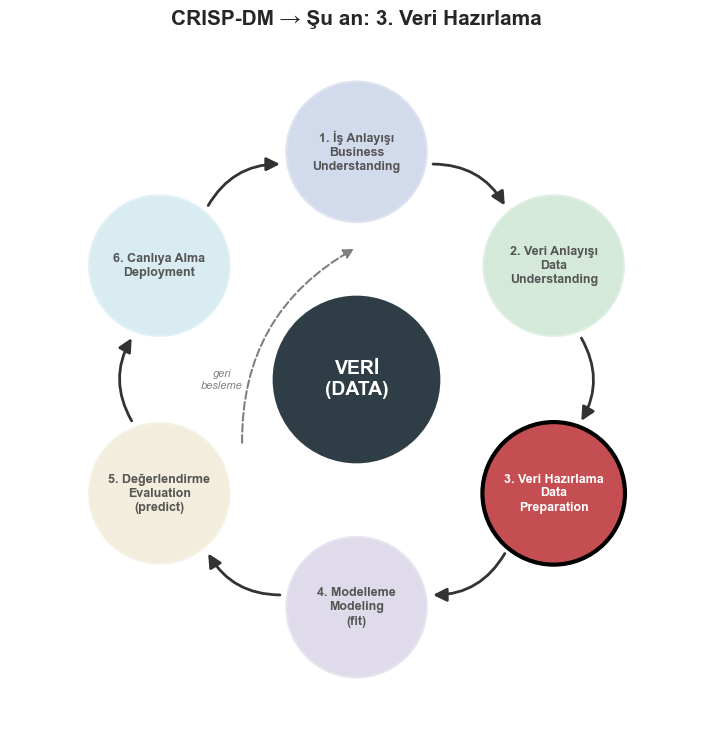

In [12]:
crisp_dm_ciz(aktif=2)

Ayırdığımız null kayıtlar için üç temel strateji vardır:

| Strateji | Kod | Artı | Eksi |
|---|---|---|---|
| **Silme** | `df.dropna()` | Basit | Veri kaybı (burada %9) |
| **İstatistikle doldurma** | `SimpleImputer(strategy="mean"/"median")` | Hızlı, güvenli | Herkese aynı değeri verir |
| **`predict` ile doldurma** | Temiz veride model `fit` → null satırlarda `predict` | Diğer kolonlardaki bilgiyi kullanır | Model hatası taşır |

Elimizde `data.csv` (eksiksiz orijinal veri) olduğu için hangi yöntemin gerçeğe daha yakın olduğunu **ölçebiliyoruz**.

In [13]:
from sklearn.linear_model import LinearRegression

gercek_veri = pd.read_csv("data.csv")
eksik_idx = df_null.index

# Yöntem 1: Ortalama ile doldurma
ortalama_yas = df_temiz["yas"].mean()

# Yöntem 2: predict ile doldurma -> temiz satırlarda yas'ı öğren, null satırlarda tahmin et
ozellikler = ["boy", "kilo", "ulke", "cinsiyet"]
X_temiz = pd.get_dummies(df_temiz[ozellikler], drop_first=True).astype(float)
y_temiz = df_temiz["yas"]

yas_modeli = LinearRegression().fit(X_temiz, y_temiz)                      # fit  = öğren
X_null = (pd.get_dummies(df_null[ozellikler])
            .reindex(columns=X_temiz.columns, fill_value=0).astype(float))
yas_tahmin = yas_modeli.predict(X_null)                                     # predict = uygula

karsilastirma = pd.DataFrame({
    "gercek_yas": gercek_veri.loc[eksik_idx, "yas"].values,
    "ortalama_ile": round(ortalama_yas, 2),
    "predict_ile": yas_tahmin.round(2),
}, index=eksik_idx)
karsilastirma["hata_ortalama"] = (karsilastirma["ortalama_ile"] - karsilastirma["gercek_yas"]).abs()
karsilastirma["hata_predict"] = (karsilastirma["predict_ile"] - karsilastirma["gercek_yas"]).abs()
karsilastirma

,gercek_yas,ortalama_ile,predict_ile,hata_ortalama,hata_predict
12,39,28.45,38.76,10.55,0.24
16,23,28.45,38.18,5.45,15.18


**Yorum:**

- **Satır 12** (gerçek yaş 39): Ortalama 28.45 verip **~10.5 yıl** hata yaparken, `predict` 38.76 tahmin ederek yalnızca **~0.2 yıl** hata yaptı.
- **Satır 16** (gerçek yaş 23): Ortalama **~5.5 yıl**, `predict` ise **~15.2 yıl** hata yaptı (38.18 tahmin etti).

Yani `predict` ile doldurma **her zaman** daha iyi değildir: yaş ile boy/kilo arasındaki ilişki yetişkinlerde zayıftır ve 20 satırlık veriyle öğrenilen model yanılabilir. Ders: doldurma yöntemini **veriyle doğrulayarak** seçmek gerekir.

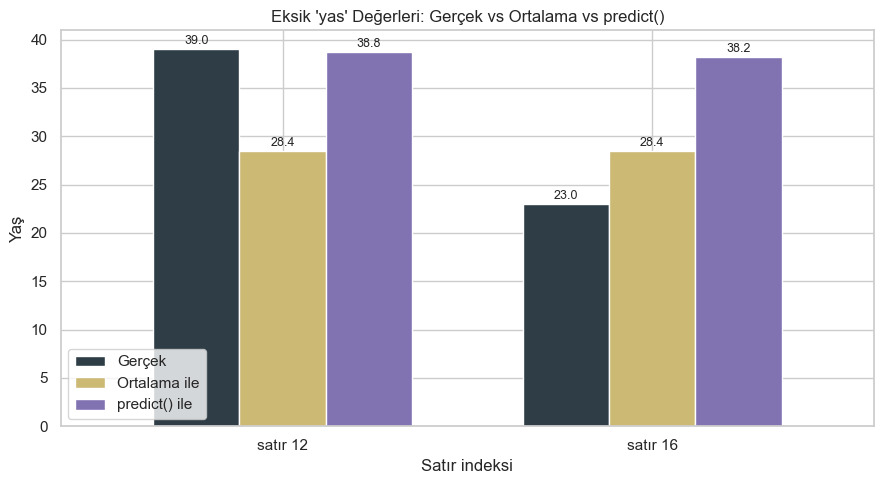

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
karsilastirma[["gercek_yas", "ortalama_ile", "predict_ile"]].plot(
    kind="bar", ax=ax, color=["#2F3E46", "#CCB974", "#8172B2"], width=0.7)
ax.set_title("Eksik 'yas' Değerleri: Gerçek vs Ortalama vs predict()")
ax.set_xlabel("Satır indeksi"); ax.set_ylabel("Yaş")
ax.set_xticklabels([f"satır {i}" for i in karsilastirma.index], rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.5), ha="center", fontsize=9)
ax.legend(["Gerçek", "Ortalama ile", "predict() ile"])
plt.tight_layout()
plt.show()

**Yorum:** Grafik iki yöntemin farklı satırlarda farklı başarı gösterdiğini net biçimde ortaya koyuyor. Bu yüzden modelleme pipeline'ında **aykırı değerlere dayanıklı olan medyan** ile doldurmayı tercih edeceğiz ve bir **"yas_eksik" göstergesi** gibi bilgilerin de faydalı olabileceğini aklımızda tutacağız.

### ✂️ Önce Train/Test ayrımı, SONRA ön işleme

**Altın kural:** Imputer, scaler, encoder gibi dönüştürücüler **sadece eğitim verisinde `fit`** edilmelidir. Aksi halde test setinin bilgisi eğitime sızar (**data leakage**). Bunu garanti etmenin en temiz yolu `Pipeline` + `ColumnTransformer` kullanmaktır.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = ham_veri[["ulke", "boy", "kilo", "yas"]]   # Ham (NaN içeren) veriyi veriyoruz; doldurmayı pipeline yapacak
y = ham_veri["cinsiyet"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train'deki NaN:", X_train.isnull().sum().sum(), "| Test'teki NaN:", X_test.isnull().sum().sum())
print("Train sınıf dağılımı:", y_train.value_counts().to_dict())

sayisal = ["boy", "kilo", "yas"]
kategorik = ["ulke"]

on_isleme = ColumnTransformer([
    ("sayisal", Pipeline([
        ("doldur", SimpleImputer(strategy="median")),  # NaN -> train medyanı
        ("olcekle", StandardScaler()),
    ]), sayisal),
    ("kategorik", OneHotEncoder(handle_unknown="ignore"), kategorik),
])

Train: (15, 4) | Test: (7, 4)
Train'deki NaN: 2 | Test'teki NaN: 0
Train sınıf dağılımı: {'k': 8, 'e': 7}


**Yorum:** Veri %70/%30 oranında **15 eğitim / 7 test** satırına ayrıldı; `stratify=y` sayesinde her iki sette de e/k oranı korunur. NaN'lar pipeline içinde **yalnızca train medyanı** ile doldurulacak; `ulke` kolonu One-Hot, sayısal kolonlar standartlaştırılacak.

---
## 4️⃣ Modelleme (Modeling) — `fit`

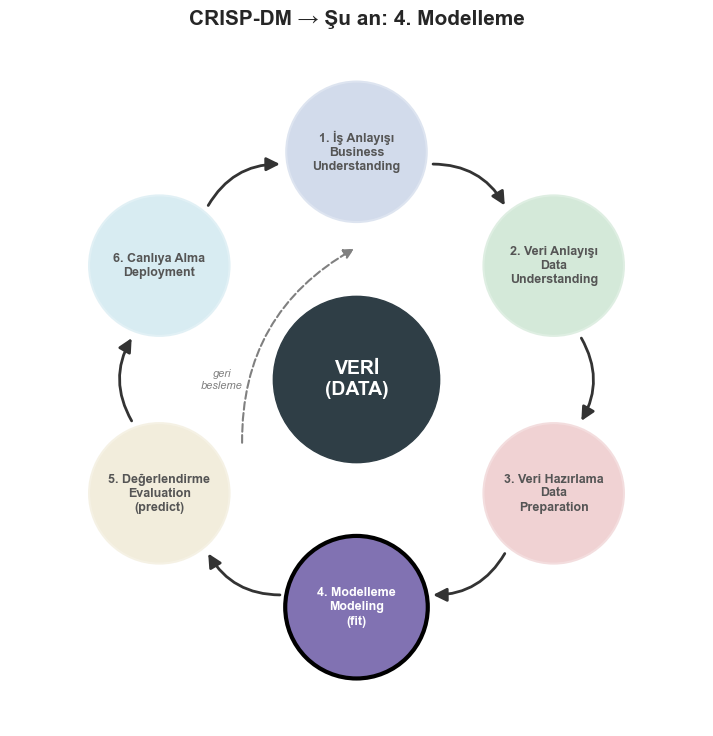

In [16]:
crisp_dm_ciz(aktif=3)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modeller = {
    "Lojistik Regresyon": Pipeline([("on_isleme", on_isleme), ("model", LogisticRegression())]),
    "Karar Ağacı (max_depth=3)": Pipeline([("on_isleme", on_isleme),
                                           ("model", DecisionTreeClassifier(max_depth=3, random_state=42))]),
}

for ad, pipe in modeller.items():
    pipe.fit(X_train, y_train)    # Imputer + Scaler + Encoder + Model birlikte SADECE train'de öğrenir
    print(f"✔ {ad} eğitildi")

✔ Lojistik Regresyon eğitildi
✔ Karar Ağacı (max_depth=3) eğitildi


**Yorum:** İki farklı model eğitildi: doğrusal bir model (**Lojistik Regresyon**) ve doğrusal olmayan bir model (**Karar Ağacı**). Ağacın derinliği aşırı öğrenmeyi (overfitting) sınırlamak için 3 ile kısıtlandı.

---
## 5️⃣ Değerlendirme (Evaluation) — `predict` ve `predict_proba`

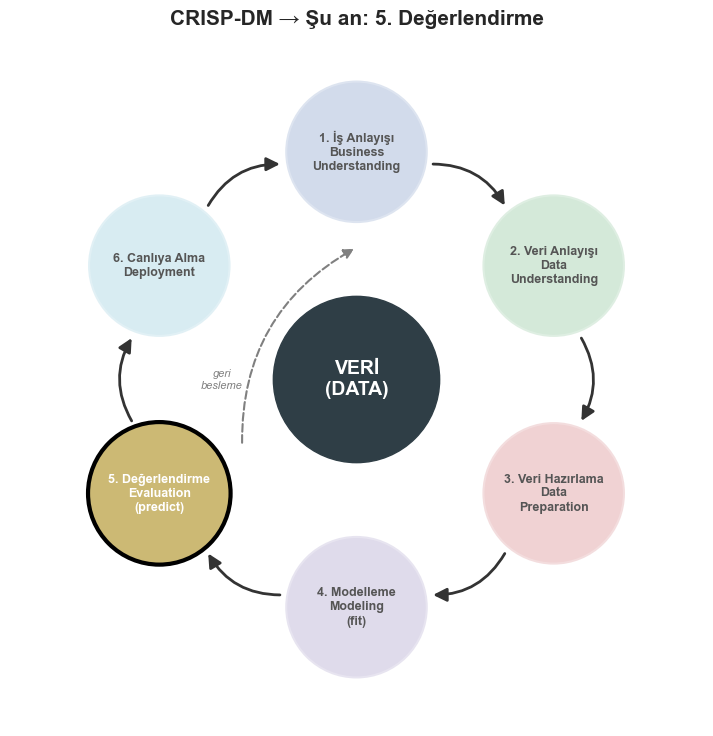

In [18]:
crisp_dm_ciz(aktif=4)

In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sonuclar = {}
for ad, pipe in modeller.items():
    y_pred_train = pipe.predict(X_train)   # predict: eğitim verisi
    y_pred_test = pipe.predict(X_test)     # predict: hiç görülmemiş test verisi
    sonuclar[ad] = {"train_acc": accuracy_score(y_train, y_pred_train),
                    "test_acc": accuracy_score(y_test, y_pred_test),
                    "y_pred": y_pred_test}
    print(f"===== {ad} =====")
    print(classification_report(y_test, y_pred_test, zero_division=0))

sonuc_tablo = pd.DataFrame({ad: {"Train Accuracy": s["train_acc"], "Test Accuracy": s["test_acc"]}
                            for ad, s in sonuclar.items()}).T.round(3)
sonuc_tablo

===== Lojistik Regresyon =====
              precision    recall  f1-score   support

           e       0.75      0.75      0.75         4
           k       0.67      0.67      0.67         3

    accuracy                           0.71         7
   macro avg       0.71      0.71      0.71         7
weighted avg       0.71      0.71      0.71         7

===== Karar Ağacı (max_depth=3) =====
              precision    recall  f1-score   support

           e       0.80      1.00      0.89         4
           k       1.00      0.67      0.80         3

    accuracy                           0.86         7
   macro avg       0.90      0.83      0.84         7
weighted avg       0.89      0.86      0.85         7



,Train Accuracy,Test Accuracy
Lojistik Regresyon,0.8,0.714
Karar Ağacı (max_depth=3),1.0,0.857


**Yorum:**

- **Lojistik Regresyon:** Train %80, Test **%71.4** (7 test örneğinden 5'i doğru).
- **Karar Ağacı:** Train %100, Test **%85.7** (7 örnekten 6'sı doğru).

Karar ağacı testte daha iyi görünse de train'de %100 olması ezberleme eğilimine işaret eder. Test seti yalnızca 7 satır olduğu için **tek bir tahmin farkı ~%14 puan** değiştirir; bu fark istatistiksel olarak güvenilir değildir.

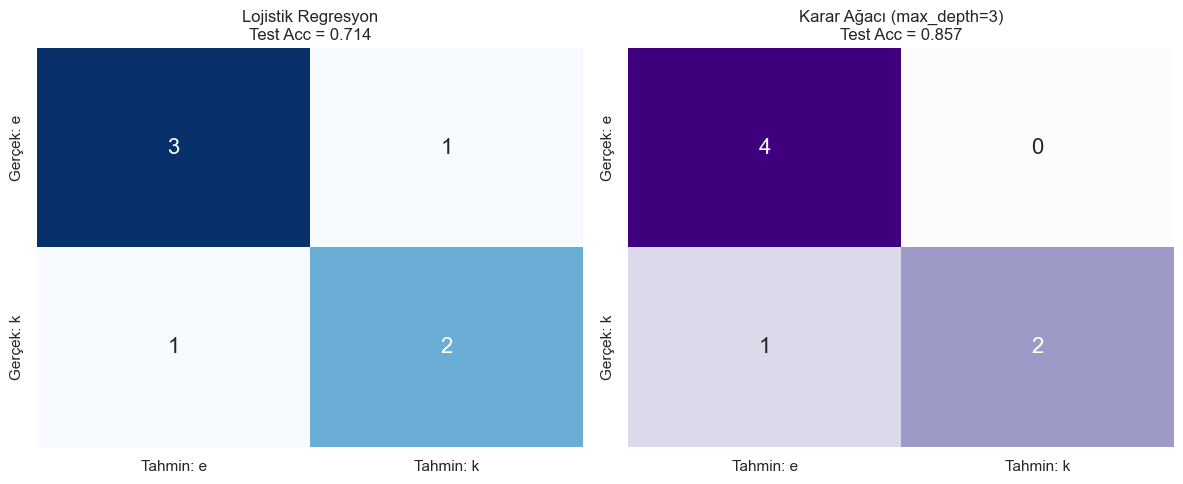

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (ad, s), cmap in zip(axes, sonuclar.items(), ["Blues", "Purples"]):
    cm = confusion_matrix(y_test, s["y_pred"], labels=["e", "k"])
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                xticklabels=["Tahmin: e", "Tahmin: k"], yticklabels=["Gerçek: e", "Gerçek: k"],
                annot_kws={"size": 16})
    ax.set_title(f"{ad}\nTest Acc = {s['test_acc']:.3f}")
plt.tight_layout()
plt.show()

**Yorum:** Lojistik Regresyon 1 erkeği kadın, 1 kadını erkek olarak tahmin etmiş (2 hata). Karar Ağacı tüm erkekleri doğru bilmiş, yalnızca 1 kadını erkek olarak sınıflandırmış (1 hata). Hatalar genellikle boyu/kilosu karşı cinsiyetin tipik aralığına düşen kişilerde oluşur.

In [21]:
# predict_proba: her test örneği için sınıf olasılıkları
lr_pipe = modeller["Lojistik Regresyon"]
olasiliklar = pd.DataFrame(lr_pipe.predict_proba(X_test), columns=[f"P({c})" for c in lr_pipe.classes_], index=X_test.index)
olasilik_tablo = pd.concat([X_test, olasiliklar.round(3),
                            pd.Series(lr_pipe.predict(X_test), index=X_test.index, name="tahmin"),
                            y_test.rename("gercek")], axis=1)
olasilik_tablo

,ulke,boy,kilo,yas,P(e),P(k),tahmin,gercek
9,us,185,105,33.0,0.706,0.294,e,e
6,tr,190,80,25.0,0.825,0.175,e,e
8,tr,177,60,22.0,0.679,0.321,e,k
5,tr,180,90,30.0,0.838,0.162,e,e
15,fr,174,70,47.0,0.267,0.733,k,e
14,us,167,62,55.0,0.061,0.939,k,k
21,fr,166,56,42.0,0.202,0.798,k,k


**Yorum:** `predict()` aslında `predict_proba()` çıktısında olasılığı **0.5'in üzerinde** olan sınıfı seçer. Olasılığı 0.5'e yakın olan satırlar modelin **kararsız** kaldığı örneklerdir; iş tarafında eşik (threshold) değiştirilerek daha temkinli kararlar verilebilir.

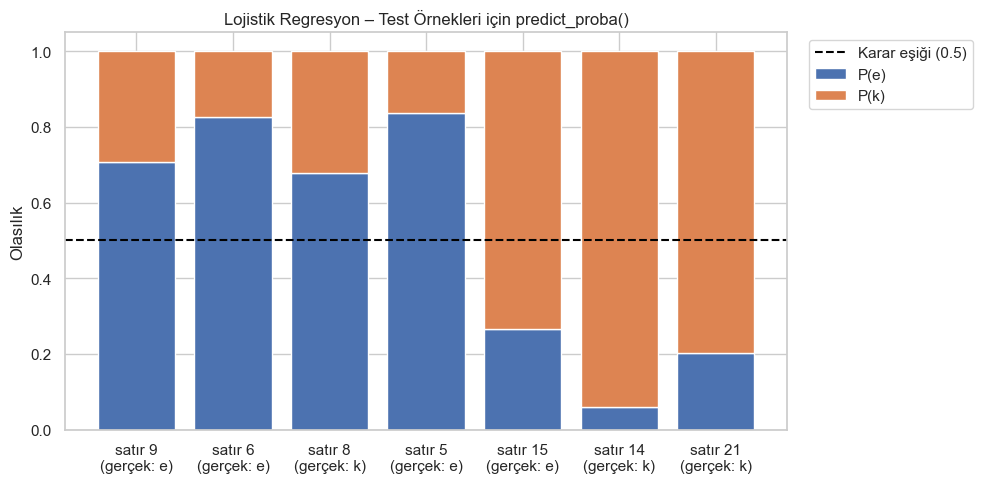

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
etiketler = [f"satır {i}\n(gerçek: {g})" for i, g in zip(olasilik_tablo.index, olasilik_tablo["gercek"])]
ax.bar(etiketler, olasilik_tablo["P(e)"], color="#4C72B0", label="P(e)")
ax.bar(etiketler, olasilik_tablo["P(k)"], bottom=olasilik_tablo["P(e)"], color="#DD8452", label="P(k)")
ax.axhline(0.5, color="black", linestyle="--", label="Karar eşiği (0.5)")
ax.set_ylabel("Olasılık"); ax.set_title("Lojistik Regresyon – Test Örnekleri için predict_proba()")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Yorum:** Mavi çubuk 0.5 çizgisini geçtiğinde `predict()` sonucu `e`, geçmediğinde `k` olur. Çizgiye yakın çubuklar yanlış tahminlerin çıktığı bölgedir.

---
## 6️⃣ Canlıya Alma (Deployment) — Modeli Kaydet, Yükle, `predict` Et

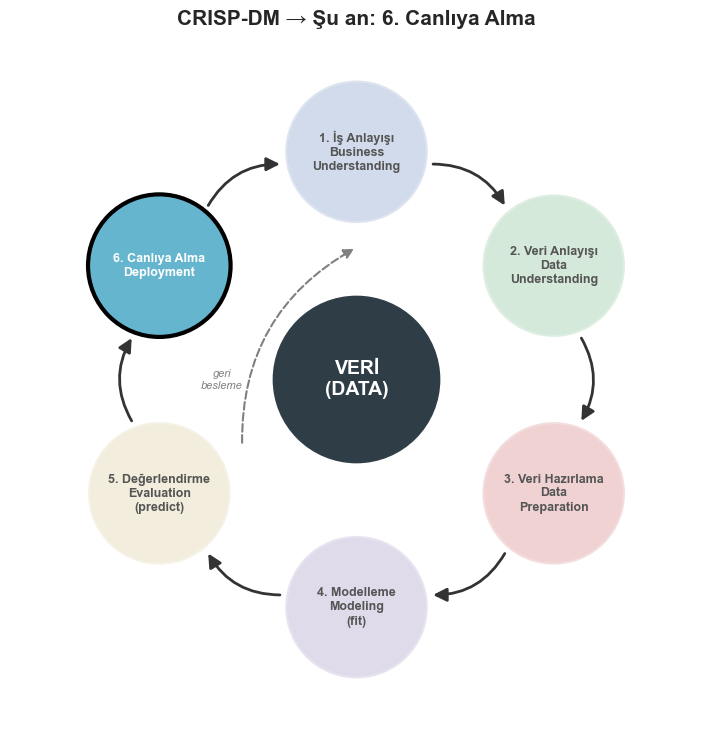

In [23]:
crisp_dm_ciz(aktif=5)

In [24]:
import joblib

secilen_model = modeller["Lojistik Regresyon"]   # Daha az ezberleyen, daha kararlı model
joblib.dump(secilen_model, "cinsiyet_modeli.pkl")

# --- Canlı ortamda (ör. bir API içinde) ---
yuklu_model = joblib.load("cinsiyet_modeli.pkl")

yeni_kisiler = pd.DataFrame([
    {"ulke": "tr", "boy": 182, "kilo": 85, "yas": 30},
    {"ulke": "fr", "boy": 160, "kilo": 52, "yas": np.nan},   # Eksik yaş -> pipeline otomatik doldurur
])
yeni_kisiler["tahmin"] = yuklu_model.predict(yeni_kisiler[["ulke", "boy", "kilo", "yas"]])
yeni_kisiler["P(e)"] = yuklu_model.predict_proba(yeni_kisiler[["ulke", "boy", "kilo", "yas"]])[:, 0].round(3)
yeni_kisiler

,ulke,boy,kilo,yas,tahmin,P(e)
0,tr,182,85,30.0,e,0.805
1,fr,160,52,NaN,k,0.360


**Yorum:** Model, ön işleme adımlarıyla birlikte **tek bir pipeline dosyası** olarak kaydedildi. Bu sayede canlı ortamda gelen yeni veride `yas` eksik olsa bile pipeline onu train medyanıyla doldurup `predict` yapabilir. Daha az ezberleyen olduğu için Lojistik Regresyon seçildi; veri büyüdükçe bu karar çapraz doğrulama (cross-validation) ile yeniden değerlendirilmelidir.

---
## 📋 Özet

### Q&A

- **`predict` nedir?** Eğitilmiş (`fit` edilmiş) bir modelin, yeni girdiler (X) için hedef değeri (ŷ) üretmesini sağlayan metottur. Sınıflandırmada etiket, regresyonda sayı döndürür; `predict_proba` ise sınıf olasılıklarını verir.
- **Tahminlemede nerede kullanılır?** CRISP-DM'in **Değerlendirme** (test setinde metrik hesaplama) ve **Canlıya Alma** (yeni veri için anlık tahmin) adımlarında; ayrıca **Veri Hazırlama**'da eksik değerleri tahmin ederek doldurmak için.
- **Ham veriden null'lar nasıl ayrılır?** Veri `na_values` ile gizli null'lar da yakalanarak okunur → `isnull().sum()` ile tespit edilir → `maske = df.isnull().any(axis=1)` ile `df[maske]` (null) ve `df[~maske]` (temiz) olarak ikiye bölünür.

### Data Analysis Key Findings

- 22 satırlık ham veride yalnızca `yas` kolonunda **2 eksik (%9.09)** vardı; 20 temiz + 2 null kayıt olarak ayrıldı.
- Eksik yaş doldurmada `predict` (Lineer Regresyon) satır 12'de ortalamadan çok daha iyi (hata 0.2 vs 10.5 yıl), satır 16'da ise daha kötü (hata 15.2 vs 5.5 yıl) sonuç verdi.
- Cinsiyet sınıflandırmasında Lojistik Regresyon test doğruluğu **%71.4**, Karar Ağacı **%85.7**; ancak ağacın train doğruluğu %100 olduğundan ezberleme riski taşıyor.

### Insights or Next Steps

- Test seti çok küçük (7 satır); güvenilir model seçimi için **k-fold cross-validation** ve daha fazla veri gerekli.
- Eksik veri oranı arttığında `KNNImputer` veya `IterativeImputer` (predict tabanlı) yöntemleri pipeline içinde denenebilir.